# 13 · Robustness: label definition, null partitions, validation distance, earthquake adjustment
Analyses added in revision (`src/robustness.py`):
* **R1** contiguous random regions with the ward size distribution as a second null for ward ICC;
* **R2** every ward result repeated without ponds, without seasonal sources, and for perennial springs only;
* **R3** how close test sources are to training sources under each validation design;
* **R4** earthquake exposure with ward fixed effects and Moran eigenvector maps.

The data show ward-level structure. They suggest, but do not prove, that collection practices produced it.

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

## R2 · Sensitivity subsets

In [2]:
s = table("rb_sensitivity_subsets.csv").set_index("subset").T
s

subset,all sources,springs only (ponds excluded),perennial only (seasonal excluded),perennial springs only
n,5689.0000,5168.0000,4759.0000,4477.0000
n_dried,1521.0000,1264.0000,934.0000,835.0000
drying_rate,0.2674,0.2446,0.1963,0.1865
ward_icc,0.1318,0.1399,0.1704,0.1847
ward_grid_q975,0.1057,0.1091,0.1211,0.1346
ward_p_grid,0.0050,0.0050,0.0050,0.0050
ward_region_q025,0.0810,0.0833,0.0866,0.0947
ward_region_q975,0.1107,0.1124,0.1260,0.1381
ward_p_region,0.0050,0.0050,0.0050,0.0050
catchment_T2_icc,0.1221,0.1249,0.1518,0.1633


## R1 · Ward ICC against grids and contiguous random regions

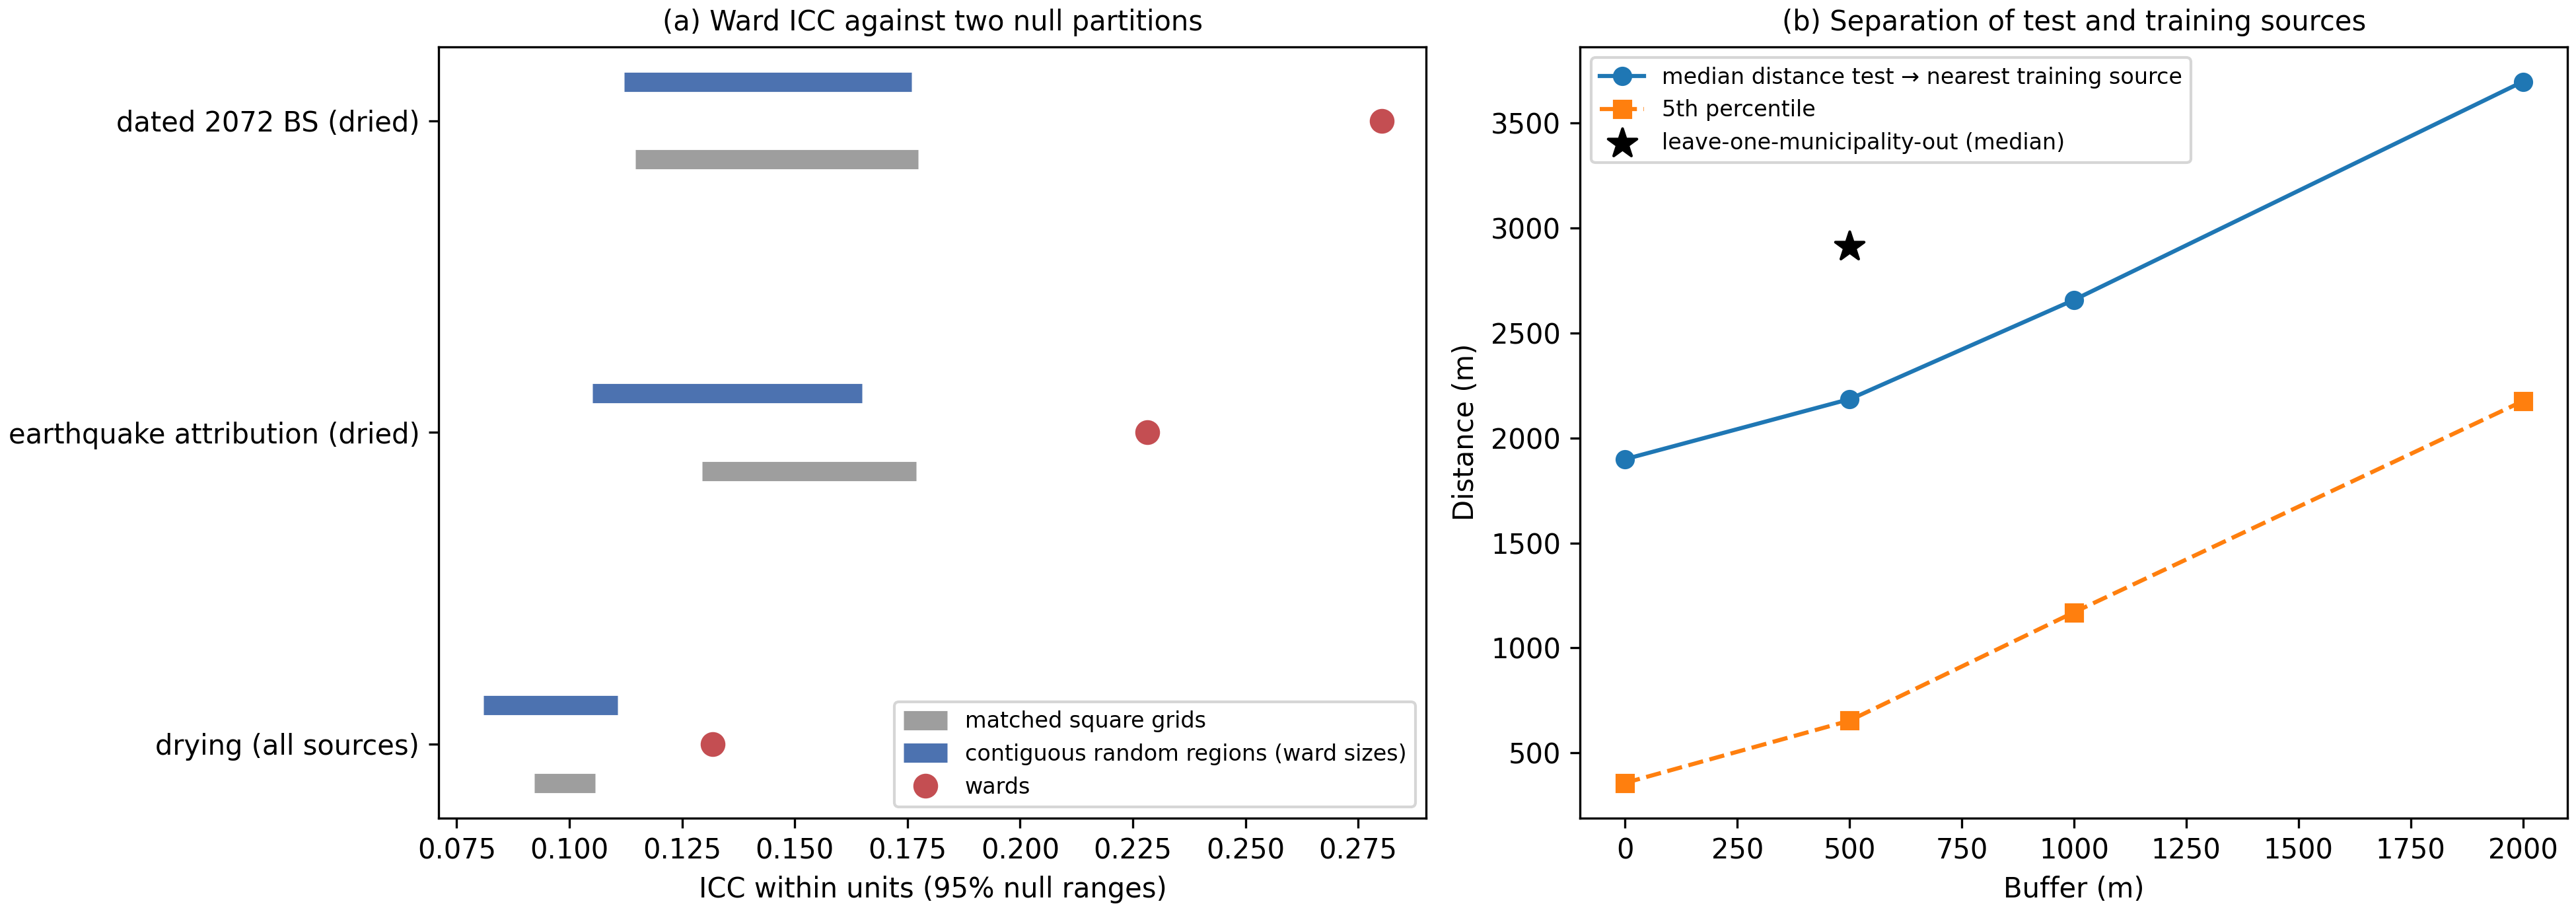

In [3]:
fig("rb_robustness.png")

Interactive: draw a smaller region null (50 partitions) for any outcome. Change `outcome` or `n_rep`.

In [4]:
from src.graph_builder import load_master, coords_to_metric
from src.catchment_analysis import icc1
from src.robustness import neighbours, region_null
df = load_master()
coords = coords_to_metric(df.latitude.to_numpy(), df.longitude.to_numpy())
ward = (df.municipality.astype(str) + "_" + df.ward.astype(str)).to_numpy()
sizes = pd.Series(ward).value_counts().to_numpy()
outcome, n_rep = df.target_dried.to_numpy().astype(float), 50
parts = region_null(neighbours(coords), sizes, coords, n_rep=n_rep, seed=1)
null = np.array([icc1(outcome, p) for p in parts])
print(f"ward ICC {icc1(outcome, ward):.3f}; random regions mean {null.mean():.3f}, 95% range "
      f"{np.quantile(null, .025):.3f}-{np.quantile(null, .975):.3f}; region sizes (one draw) "
      f"{np.percentile(np.bincount(parts[0]), [25, 50, 75])}")

ward ICC 0.132; random regions mean 0.095, 95% range 0.079-0.112; region sizes (one draw) [ 50.   74.  100.5]


## R3 · Validation distances and buffer sensitivity

In [5]:
display(table("rb_validation_distances.csv"))
b = pd.concat([pd.read_csv(M / f"benchmark_{p}_folds.csv") for p in ["main", "buffers", "lomo"]])
b = b[(b.feature_set == "env_hydro") & b.model.isin(["Logistic Regression", "Random Forest", "CatBoost"])]
b.assign(design=np.where(b.profile == "lomo", "LOMO", "buffer " + b.buffer_m.astype(int).astype(str) + " m")) \
 .pivot_table(index="design", columns="model", values="roc_auc").round(3)

,design,buffer_m,n_splits,mean_n_train,median_distance_m,p05_distance_m,share_test_within_500m,share_test_within_1km
0,leave-one-municipality-out,500.0,21,3786.7143,2912.4482,786.4436,0.0000,0.1035
1,spatial block CV,0.0,25,3413.4000,1898.8737,356.8738,0.0976,0.2525
2,spatial block CV,500.0,25,3315.7600,2185.0627,653.3694,0.0000,0.1757
3,spatial block CV,1000.0,25,3120.4400,2657.5692,1169.4188,0.0000,0.0000
4,spatial block CV,2000.0,25,2686.4000,3697.2583,2175.3718,0.0000,0.0000


model,CatBoost,Logistic Regression,Random Forest
design,,,
LOMO,0.639,0.630,0.635
buffer 0 m,0.678,0.669,0.683
buffer 1000 m,0.659,0.663,0.671
buffer 2000 m,0.642,0.650,0.651
buffer 500 m,0.670,0.668,0.681


## R4 · Earthquake exposure: associative only

In [6]:
display(table("rb_seismic_within_ward_variance.csv")); table("rb_seismic_adjusted.csv")

,variable,share_of_variance_within_wards,within_ward_sd,total_sd
0,pga_main,0.1104,1.7074,5.1380
1,pga_may12,0.1123,1.4455,4.3137
2,aftershocks_20km,0.0716,1.2609,4.7123


,model,term,coef_per_sd,ci_low,ci_high,ci_excludes_zero
0,seismic + environment,pga_main,-0.2285,-0.7043,0.0707,False
1,seismic + environment,pga_may12,0.6882,0.2419,1.0329,True
2,seismic + environment,aftershocks_20km,-0.2434,-0.5955,0.0403,False
3,seismic + environment + ward fixed effects,pga_main,-0.4426,-1.0373,0.0728,False
4,seismic + environment + ward fixed effects,pga_may12,0.3472,-0.0978,0.7780,False
5,seismic + environment + ward fixed effects,aftershocks_20km,-0.0684,-0.7204,0.3928,False
6,seismic + environment + 100 MEMs (broad and meso spatial structure),pga_main,-0.2672,-0.6996,0.0762,False
7,seismic + environment + 100 MEMs (broad and meso spatial structure),pga_may12,0.7356,0.3679,1.0370,True
8,seismic + environment + 100 MEMs (broad and meso spatial structure),aftershocks_20km,-0.2327,-0.5881,0.0470,False


Only about 11% of PGA variance lies within wards, so the ward-fixed-effect model has little exposure contrast left.
Its null result does not show that shaking has no effect, and the MEM-adjusted association does not show that it has one.

## Apriori: multiplicity summary

In [7]:
table("pm_drying_rules_summary.csv")

,consequent,n_rules,n_ward_robust,n_reversed_within_wards,median_heldout_replication,median_share_wards_lift_gt1
0,active,2337,1903,4,1.0,0.7778
1,dried,3321,2613,11,1.0,0.6842
